# 第二章前 15 图：Excel 数据到可视化

本 Notebook 使用 **pandas + NumPy + Matplotlib**，从随附 Excel 读取数据，逐图重建原模板的图表结构、深蓝背景、配色、标题、标签和图例。所有图形均由代码绘制。

## 运行方法

1. 先解压完整项目包，保留 `data`、`assets/fonts`、`src` 和 `notebooks` 目录。
2. 在 Jupyter Notebook 打开本文件，选择 Python 3 内核。
3. 首次缺少依赖时，新建一个代码单元格运行下面的安装命令，然后重启内核。
4. 选择 **运行 → 运行所有单元格**。各图依次显示，PNG 同时保存到 `outputs/charts` 文件夹。

```python
%pip install numpy pandas matplotlib openpyxl
```

**复刻边界：**字体度量、抗锯齿和平滑算法随软件而异，因此这里提供可重算的代码复刻，不能保证与 Excel 截图逐像素相同。第 14 图按源文件的 90% 内径绘制，第 15 图用几何裁切实现水位；它们与个别办公软件的图片填充渲染效果可能不同。源模板的标题、统计日期和说明文字按原文保留；更改数据后请同步核对这些说明和固定坐标轴上限。

## 0. 公共设置与绘图工具

先运行本单元格，再运行需要的单图单元格。优先使用微软雅黑，并附带思源黑体作为中文字体备选。`header=1` 表示 Excel 第 2 行为表头；甘特图表头位于第 3 行，单独使用 `header=2`。

In [1]:
%matplotlib inline
from pathlib import Path
from io import BytesIO
import math
import zipfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, colors
from matplotlib.font_manager import FontProperties
from matplotlib.patches import Rectangle, FancyBboxPatch, PathPatch, Circle, Wedge
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FuncFormatter

# 从脚本目录或 Notebook 工作目录向上定位项目，支持不同启动目录。
def find_project_root():
    candidates = [Path.cwd()]
    if '__file__' in globals():
        candidates.insert(0, Path(__file__).resolve().parent)
    for start in candidates:
        for candidate in (start, *start.parents):
            if (candidate / 'data' / '第二章 图表(前15).xlsx').is_file():
                return candidate
    raise FileNotFoundError('找不到项目 data 目录。请保留完整项目结构，并从项目根目录或 notebooks 目录运行。')

BASE_DIR = find_project_root()
EXCEL_FILE = BASE_DIR / 'data' / '第二章 图表(前15).xlsx'
OUT_DIR = BASE_DIR / 'outputs' / 'charts'
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not EXCEL_FILE.exists():
    raise FileNotFoundError(f'未找到 {EXCEL_FILE.name}。请将 Excel 放在项目 data 目录，或修改 EXCEL_FILE。')

for font_file in (BASE_DIR / 'assets' / 'fonts').glob('*.otf'):
    font_manager.fontManager.addfont(str(font_file))
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((s for s in ['Microsoft YaHei', '微软雅黑', 'Noto Sans CJK SC', 'SimHei', 'PingFang SC']
             if s in available_fonts), 'DejaVu Sans')
if FONT == 'DejaVu Sans':
    raise RuntimeError('缺少中文字体。请保留配套 assets/fonts 文件夹，或安装微软雅黑/黑体后重启内核。')
plt.rcParams.update({'font.family': FONT, 'axes.unicode_minus': False,
                     'figure.dpi': 110, 'savefig.dpi': 180,
                     'svg.fonttype': 'path', 'axes.linewidth': 0.6})
BG, WHITE = '#1A1E43', '#F2F2F2'
BLUE, PINK, LIGHT_BLUE = '#0070C0', '#E74E69', '#82ADD7'
NS = {'c': 'http://schemas.openxmlformats.org/drawingml/2006/chart',
      'a': 'http://schemas.openxmlformats.org/drawingml/2006/main',
      'd': 'http://schemas.openxmlformats.org/drawingml/2006/chartDrawing'}
SHEETS = pd.ExcelFile(EXCEL_FILE, engine='openpyxl').sheet_names


def read_table(number, usecols, nrows, header=1):
    """按原表的准确位置读取；不依赖 Unnamed 列名，也不读取右侧辅助图形。"""
    df = pd.read_excel(EXCEL_FILE, sheet_name=SHEETS[number-1],
                       usecols=usecols, header=header, nrows=nrows,
                       engine='openpyxl')
    df.columns = [str(c).strip() for c in df.columns]
    if df.iloc[:, 0].isna().any():
        raise ValueError(f'{SHEETS[number-1]} 的数据区域含空白分类，请检查原表。')
    return df


def numeric(df, column):
    return pd.to_numeric(df[column], errors='raise').to_numpy(dtype=float)


def xml_color(element, default=WHITE):
    if element is None:
        return default
    rgb = element.find('.//a:srgbClr', NS)
    scheme = element.find('.//a:schemeClr', NS)
    if rgb is not None:
        value, node = '#' + rgb.get('val'), rgb
    elif scheme is not None:
        palette = {'bg1': '#FFFFFF', 'lt1': '#FFFFFF', 'dk1': '#000000',
                   'tx1': '#000000', 'accent1': BLUE, 'accent2': '#ED7D31'}
        value, node = palette.get(scheme.get('val'), default), scheme
    else:
        return default
    rgb_array = np.array(colors.to_rgb(value))
    mod, off, alpha = 1., 0., 1.
    for child in node:
        key = child.tag.split('}')[-1]
        if key == 'lumMod': mod = int(child.get('val')) / 100000
        elif key == 'lumOff': off = int(child.get('val')) / 100000
        elif key == 'alpha': alpha = int(child.get('val')) / 100000
    return (*np.clip(rgb_array * mod + off, 0, 1), alpha)


def template_xml(number):
    """只读取 Excel 内的矢量样式和文本，不提取或粘贴模板截图。"""
    if number == 7:
        return None, None
    chart_number = number if number < 7 else number - 1
    with zipfile.ZipFile(EXCEL_FILE) as archive:
        chart = ET.fromstring(archive.read(f'xl/charts/chart{chart_number}.xml'))
        rels = ET.fromstring(archive.read(f'xl/charts/_rels/chart{chart_number}.xml.rels'))
        shape_ref = chart.find('c:userShapes', NS)
        shape_root = None
        if shape_ref is not None:
            rid = shape_ref.get('{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id')
            rel = next(r for r in rels if r.get('Id') == rid)
            name = Path(rel.get('Target')).name
            shape_root = ET.fromstring(archive.read('xl/drawings/' + name))
    return chart, shape_root


# 保留各示例画布的长宽比例；绘图区位置直接读取 Excel 的 manualLayout。
ASPECTS = {1:866/608, 2:866/593, 3:866/607, 4:866/606, 5:865/579,
           6:866/578, 7:748/373, 8:866/581, 9:865/636, 10:924/579,
           11:865/624, 12:866/590, 13:865/613, 14:866/606, 15:865/604}


def canvas(number):
    fig = plt.figure(figsize=(6, 6/ASPECTS[number]), facecolor=BG)
    chart, shape_root = template_xml(number)
    if chart is not None:
        layout = chart.find('c:chart/c:plotArea/c:layout/c:manualLayout', NS)
        if layout is not None:
            d = {e.tag.split('}')[-1]: e.get('val') for e in layout}
            x, top, w, h = (float(d[k]) for k in ('x', 'y', 'w', 'h'))
            bounds = [x, 1-top-h, w, h]
        else:
            bounds = [.25, .16, .50, .60]
    else:
        bounds = [.12, .22, .76, .43]
    ax = fig.add_axes(bounds, facecolor=BG)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(colors=WHITE, labelsize=9, length=0, pad=3)
    ax.set_axisbelow(True)
    return fig, ax, shape_root


def text_width(fig, text, size, weight='normal'):
    prop = FontProperties(family=FONT, size=size, weight=weight)
    return fig.canvas.get_renderer().get_text_width_height_descent(text, prop, False)[0] / fig.dpi


def wrap_text(fig, text, size, width, weight='normal'):
    lines, line = [], ''
    for ch in text:
        if ch == '\n' or (line and text_width(fig, line + ch, size, weight) > width):
            lines.append(line)
            line = '' if ch == '\n' else ch
        else:
            line += ch
    if line: lines.append(line)
    return lines or ['']


def template_text(fig, root, replacements=None, skip_text=(), skip_exact=()):
    """读取原图文本框的坐标、字号、粗细、文字颜色和段间距。"""
    if root is None: return
    replacements = replacements or {}
    fw, fh = fig.get_size_inches()
    for anchor in root:
        shape = anchor.find('d:sp', NS)
        if shape is None: continue
        body = shape.find('d:txBody', NS)
        if body is None: continue
        paragraphs = body.findall('a:p', NS)
        if not any(p.find('.//a:t', NS) is not None for p in paragraphs): continue
        actual_text = ''.join(t.text or '' for t in body.findall('.//a:t', NS))
        if actual_text in skip_exact or any(t in actual_text for t in skip_text): continue
        origin, end = anchor.find('d:from', NS), anchor.find('d:to', NS)
        if origin is None or end is None: continue
        x0, top = float(origin.find('d:x', NS).text), float(origin.find('d:y', NS).text)
        x1, bot = float(end.find('d:x', NS).text), float(end.find('d:y', NS).text)
        bp = body.find('a:bodyPr', NS)
        li = float(bp.get('lIns', '91440')) / 914400 if bp is not None else .1
        ti = float(bp.get('tIns', '45720')) / 914400 if bp is not None else .05
        ri = float(bp.get('rIns', '91440')) / 914400 if bp is not None else .1
        vcenter = bp is not None and bp.get('anchor') == 'ctr'
        cursor = top + ti/fh
        for para in paragraphs:
            text = ''.join(t.text or '' for t in para.findall('.//a:t', NS))
            for old, new in replacements.items(): text = text.replace(old, new)
            if not text: continue
            run_props = para.find('a:r/a:rPr', NS)
            if run_props is None: run_props = para.find('a:endParaRPr', NS)
            size = float(run_props.get('sz', '1100'))/100 if run_props is not None else 11
            weight = 'bold' if run_props is not None and run_props.get('b') == '1' else 'normal'
            color = xml_color(run_props)
            pp = para.find('a:pPr', NS)
            center = pp is not None and pp.get('algn') == 'ctr'
            lines = wrap_text(fig, text, size, max(.3, (x1-x0)*fw-li-ri), weight)
            spacing = para.find('a:pPr/a:lnSpc/a:spcPts', NS)
            leading = float(spacing.get('val'))/100 if spacing is not None else size*1.3
            xpos = (x0+x1)/2 if center else x0+li/fw
            ypos = (top+bot)/2 if vcenter and len(paragraphs)==1 else cursor
            fig.text(xpos, 1-ypos, '\n'.join(lines), fontsize=size, color=color,
                     weight=weight, ha='center' if center else 'left',
                     va='center' if vcenter and len(paragraphs)==1 else 'top',
                     linespacing=leading/size, zorder=20)
            cursor += max(leading, size*1.15)*len(lines)/72/fh


def category_axis(ax, labels, ymax, step=None, grid=True, ylabels=True, baseline=False):
    ax.set_xlim(-.5, len(labels)-.5)
    ax.set_xticks(np.arange(len(labels)), labels)
    ax.set_ylim(0, ymax)
    if step is not None: ax.set_yticks(np.arange(0, ymax + step*.01, step))
    if not ylabels: ax.set_yticks([])
    if grid: ax.yaxis.grid(True, color=WHITE, alpha=.20, lw=.5, ls=(0,(6,3)))
    if baseline:
        ax.spines['bottom'].set_visible(True)
        ax.spines['bottom'].set_color((1,1,1,.35))


def gradient_rect(ax, x, y, w, h, bottom, top, rounded=False):
    ramp = np.linspace(0, 1, 320)[:, None, None]
    c0, c1 = np.array(colors.to_rgba(bottom)), np.array(colors.to_rgba(top))
    img = ax.imshow(c0[None,None,:]*(1-ramp)+c1[None,None,:]*ramp,
                    extent=(x,x+w,y,y+h), origin='lower', aspect='auto',
                    interpolation='bicubic', zorder=3)
    if rounded:
        # 使用显示坐标计算圆角，避免横纵轴量纲不同造成圆角失真。
        p0, p1 = ax.transData.transform((0,0)), ax.transData.transform((1,1))
        rx = w/2
        ry = min(h/2, rx*abs((p1[0]-p0[0])/(p1[1]-p0[1])))
        k = .55228475
        verts=[(x+rx,y),(x+w-rx,y),(x+w-rx+k*rx,y),(x+w,y+ry-k*ry),(x+w,y+ry),
               (x+w,y+h-ry),(x+w,y+h-ry+k*ry),(x+w-rx+k*rx,y+h),(x+w-rx,y+h),
               (x+rx,y+h),(x+rx-k*rx,y+h),(x,y+h-ry+k*ry),(x,y+h-ry),
               (x,y+ry),(x,y+ry-k*ry),(x+rx-k*rx,y),(x+rx,y),(x+rx,y)]
        codes=[MplPath.MOVETO,MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.CLOSEPOLY]
        clip=PathPatch(MplPath(verts,codes),facecolor='none',edgecolor='none')
        ax.add_patch(clip); img.set_clip_path(clip)
    return img


def value_labels(ax, x, y, color=WHITE, size=9, offset=3, **kwargs):
    for a,b in zip(x,y):
        ax.annotate(f'{b:g}', (a,b), xytext=(0,offset), textcoords='offset points',
                    ha='center', va='bottom', color=color, fontsize=size, zorder=8, **kwargs)


def finish(fig, number, name, show=True):
    # 不使用 tight_layout/bbox_inches='tight'，保留模板边距和原始画布比例。
    path = OUT_DIR / f'{number:02d}_{name}.png'
    fig.savefig(path, dpi=180, facecolor=BG, edgecolor=BG)
    if show: plt.show()
    return fig


def smooth_curve(x, y, samples=50):
    """保形三次 Hermite 插值，经过所有原始点，避免平滑曲线产生虚假的负数。"""
    x, y = np.asarray(x,float), np.asarray(y,float)
    slopes = np.diff(y)/np.diff(x)
    tangents = np.zeros(len(y)); tangents[0],tangents[-1]=slopes[0],slopes[-1]
    for j in range(1,len(y)-1):
        if slopes[j-1]*slopes[j] > 0:
            tangents[j] = 2/(1/slopes[j-1]+1/slopes[j])
    xx, yy = [], []
    for j in range(len(x)-1):
        t=np.linspace(0,1,samples,endpoint=(j==len(x)-2)); h=x[j+1]-x[j]
        yy.extend((2*t**3-3*t**2+1)*y[j]+(t**3-2*t**2+t)*h*tangents[j]
                  +(-2*t**3+3*t**2)*y[j+1]+(t**3-t**2)*h*tangents[j+1])
        xx.extend(x[j]+t*h)
    return np.array(xx),np.array(yy)

print(f'已读取 {len(SHEETS)} 个工作表；中文字体：{FONT}；图片输出：{OUT_DIR.name}')


已读取 15 个工作表；中文字体：Noto Sans CJK SC；图片输出：charts


## 01. 渐变柱形图

数据源：Excel 第 1 个工作表，单元格 `B2:C8`，含表头。

柱高取自销售量，逐柱绘制从底部青蓝到顶部深蓝的渐变，保留六大区域和数值标签。

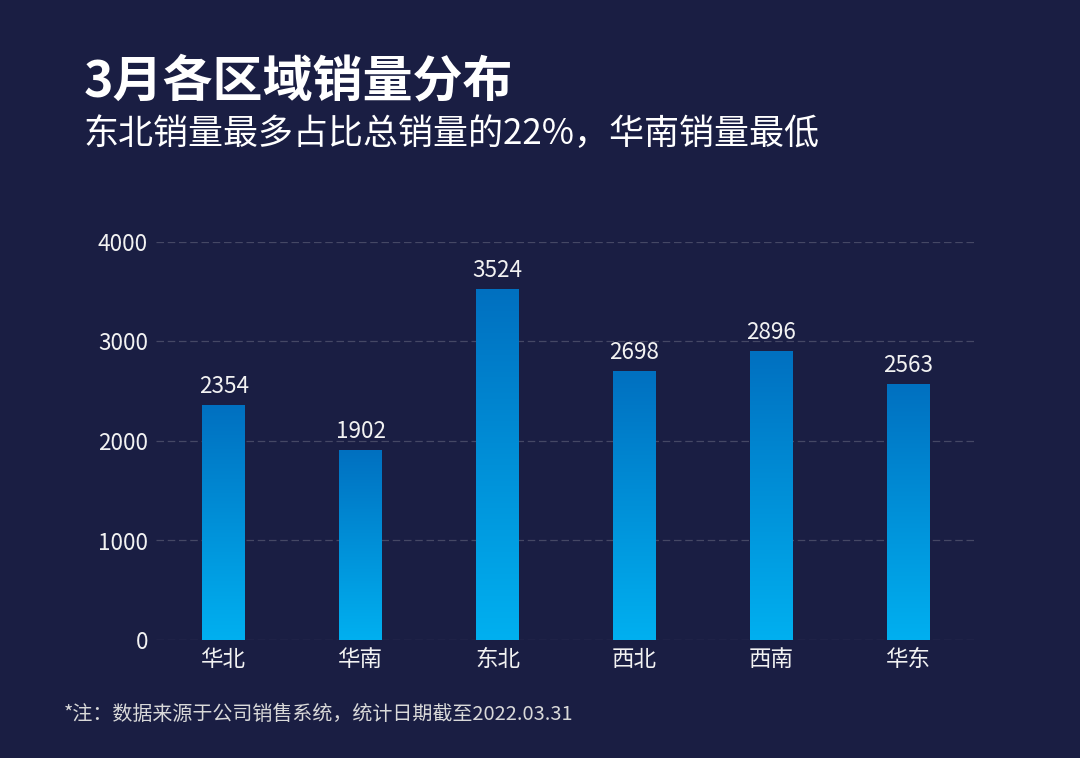

In [2]:
def chart_01(show=True):
    df = read_table(1, 'B:C', 6)
    labels, y = df['区域'].tolist(), numeric(df, '销售量')
    x = np.arange(len(y))
    fig, ax, root = canvas(1)
    category_axis(ax, labels, 4000, 1000)
    width = 1/(1+2.19)
    for xi, yi in zip(x, y):
        gradient_rect(ax, xi-width/2, 0, width, yi, '#00B0F0', '#0070C0')
    value_labels(ax, x, y)
    template_text(fig, root)
    return finish(fig, 1, '渐变柱形图', show)

fig = chart_01()
plt.close(fig)

## 02. 带均值柱形图

数据源：Excel 第 2 个工作表，单元格 `B2:D8`，含表头。

绘制销售量柱形并用 NumPy 计算平均值，再绘制黄色均值线与说明文字。

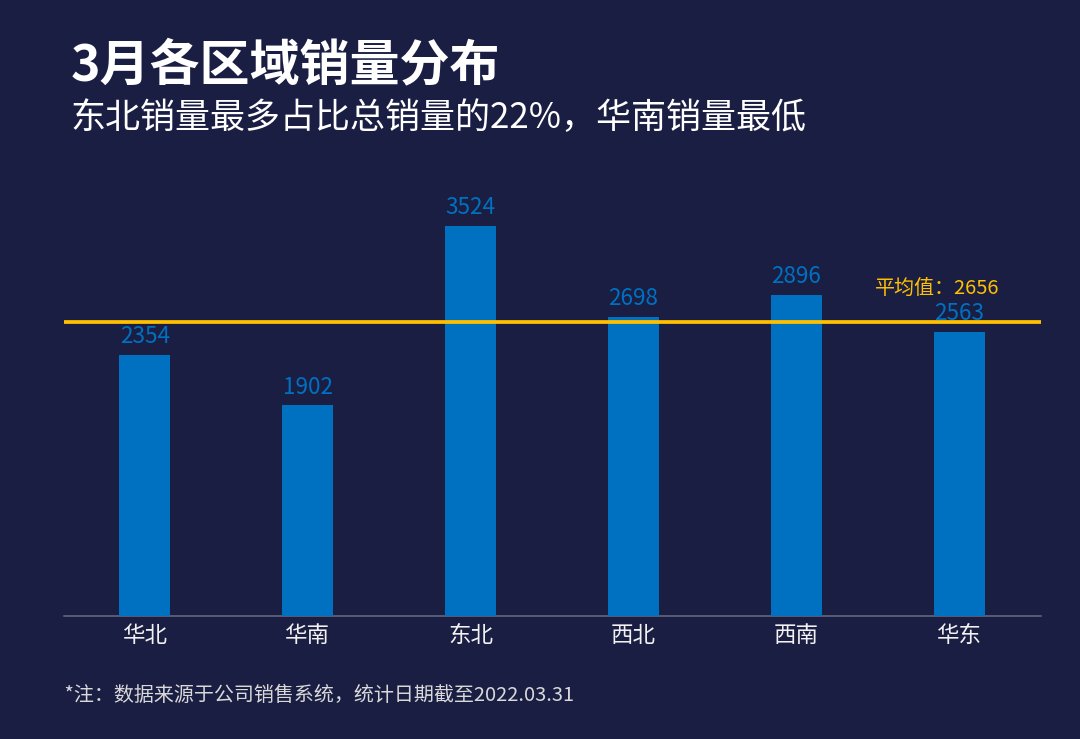

In [3]:
def chart_02(show=True):
    df = read_table(2, 'B:D', 6)
    labels, y = df['区域'].tolist(), numeric(df, '销售量')
    mean = y.mean()  # 根据销售量实时计算，避免使用可能失效的公式缓存。
    x = np.arange(len(y))
    fig, ax, root = canvas(2)
    category_axis(ax, labels, 4000, grid=False, ylabels=False, baseline=True)
    ax.bar(x, y, width=1/3.19, color=BLUE, zorder=3)
    ax.axhline(mean, color='#FFC000', linewidth=1.5, zorder=5)
    value_labels(ax, x, y, color=BLUE)
    template_text(fig, root, {'2656': f'{mean:.0f}'})
    return finish(fig, 2, '带均值柱形图', show)

fig = chart_02()
plt.close(fig)

## 03. 渐变圆角柱形图

数据源：Excel 第 3 个工作表，单元格 `B2:C8`，含表头。

用渐变图像和圆角路径裁切绘制细柱，配合淡蓝圆角数值标注及引导线。

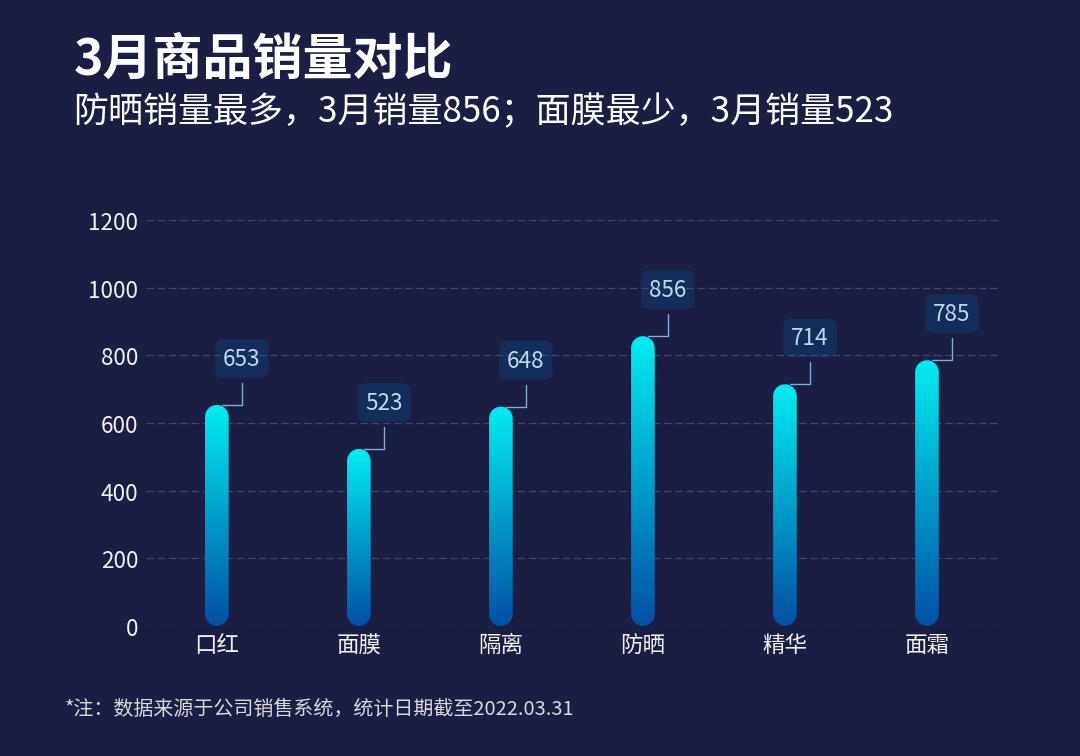

In [4]:
def chart_03(show=True):
    df = read_table(3, 'B:C', 6)
    labels, y = df['商品'].tolist(), numeric(df, '销量')
    x = np.arange(len(y))
    fig, ax, root = canvas(3)
    category_axis(ax, labels, 1200, 200)
    width = 1/6
    for xi, yi in zip(x, y):
        gradient_rect(ax, xi-width/2, 0, width, yi, '#0050A4', '#00EDF2', rounded=True)
        ax.annotate(f'{yi:g}', (xi,yi), xytext=(10,14), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, color='#BFD9EF',
                    bbox={'boxstyle':'round,pad=0.35','fc':'#0070C0','alpha':.19,'ec':'none'},
                    arrowprops={'arrowstyle':'-','color':'#82ADD7','lw':.55,
                                'connectionstyle':'angle,angleA=90,angleB=0,rad=0'}, zorder=8)
    template_text(fig, root)
    return finish(fig, 3, '渐变圆角柱形图', show)

fig = chart_03()
plt.close(fig)

## 04. 标注柱形图

数据源：Excel 第 4 个工作表，单元格 `B2:C10`，含表头。

八个商品分别使用原模板颜色，顶部数值标注沿用相同的背景色。

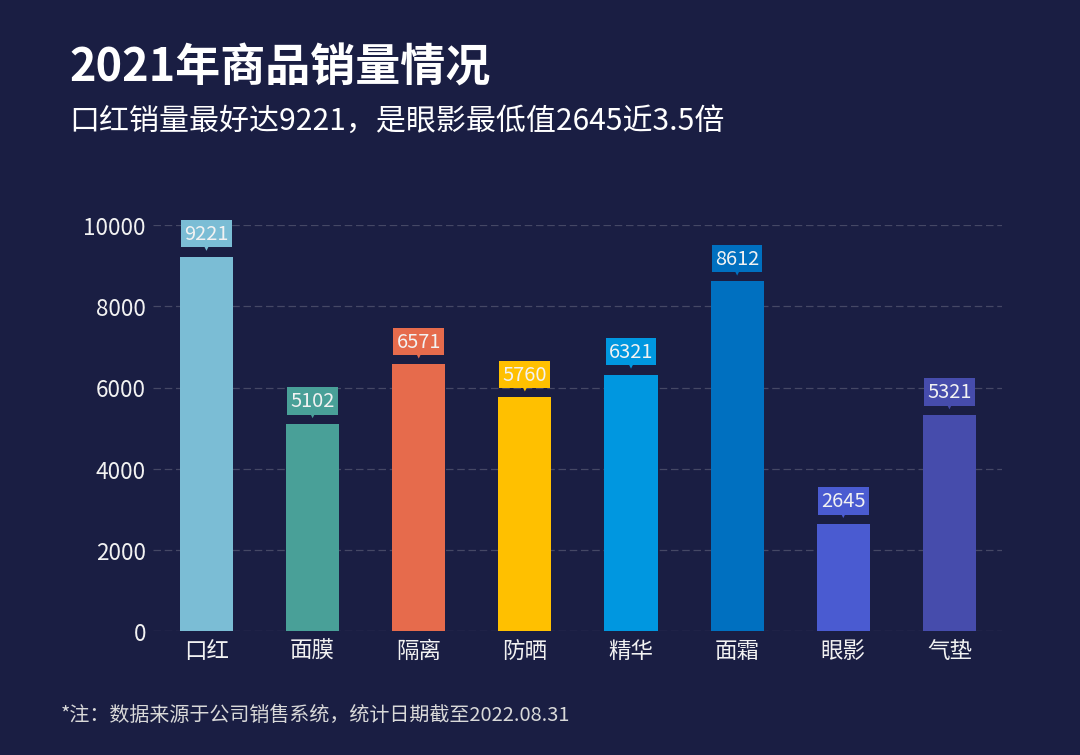

In [5]:
def chart_04(show=True):
    df = read_table(4, 'B:C', 8)
    labels, y = df.iloc[:,0].tolist(), numeric(df, '销量')
    palette = ['#7BBDD5','#49A098','#E66B4C','#FFC000','#0097E0','#0070C0','#4A5BD1','#464CAC']
    x=np.arange(len(y)); fig,ax,root=canvas(4)
    category_axis(ax, labels, 10000, 2000)
    ax.bar(x,y,width=.5,color=palette,zorder=3)
    for xi,yi,c in zip(x,y,palette):
        ax.annotate(f'{yi:g}',(xi,yi),xytext=(0,5),textcoords='offset points',
                    ha='center',va='bottom',fontsize=8,color=WHITE,
                    bbox={'boxstyle':'square,pad=.16','fc':c,'ec':'none'},zorder=8)
        ax.annotate('',(xi,yi+20),xytext=(0,5),textcoords='offset points',
                    arrowprops={'arrowstyle':'-|>','color':c,'lw':0,'mutation_scale':7})
    template_text(fig,root)
    return finish(fig,4,'标注柱形图',show)

fig = chart_04()
plt.close(fig)

## 05. 层叠柱形图

数据源：Excel 第 5 个工作表，单元格 `B2:D8`，含表头。

原模板使用重叠 30% 的簇状柱形；销售额、利润额均从零开始绘制，避免误画成堆积柱形。

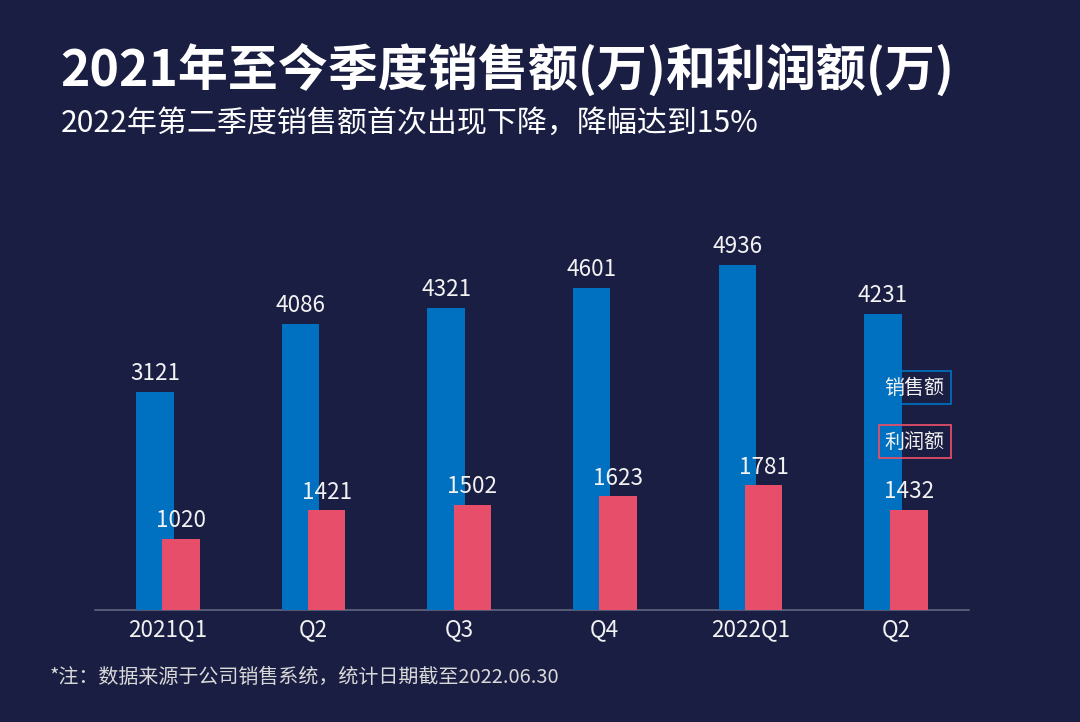

In [6]:
def chart_05(show=True):
    df=read_table(5,'B:D',6)
    sales,profit=numeric(df,'销售额'),numeric(df,'利润额')
    x=np.arange(len(df)); fig,ax,root=canvas(5)
    category_axis(ax,df['季度'].tolist(),6000,grid=False,ylabels=False,baseline=True)
    # 源图采用重叠 30% 的簇状柱形，两个指标均从零开始。
    width=1/(2-.30+2.19); shift=width*(1-.30)/2
    ax.bar(x-shift,sales,width=width,color=BLUE,zorder=3)
    ax.bar(x+shift,profit,width=width,color=PINK,zorder=4)
    value_labels(ax,x-shift,sales)
    value_labels(ax,x+shift,profit)
    template_text(fig,root,skip_exact=('销售额', '利润额'))
    for txt,c,ypos in [('销售额',BLUE,.463),('利润额',PINK,.388)]:
        fig.text(.847,ypos,txt,ha='center',va='center',fontsize=8,color=WHITE,
                 bbox={'fc':'none','ec':c,'lw':.7,'pad':2.3},zorder=20)
    return finish(fig,5,'层叠柱形图',show)

fig = chart_05()
plt.close(fig)

## 06. 蝴蝶图（销量）

数据源：Excel 第 6 个工作表，单元格 `B2:F7`，含表头。

利用重新计算的占位量，使左侧条形右端对齐；区域名称置于中间，左右分别比较 2022 年与 2021 年销量。

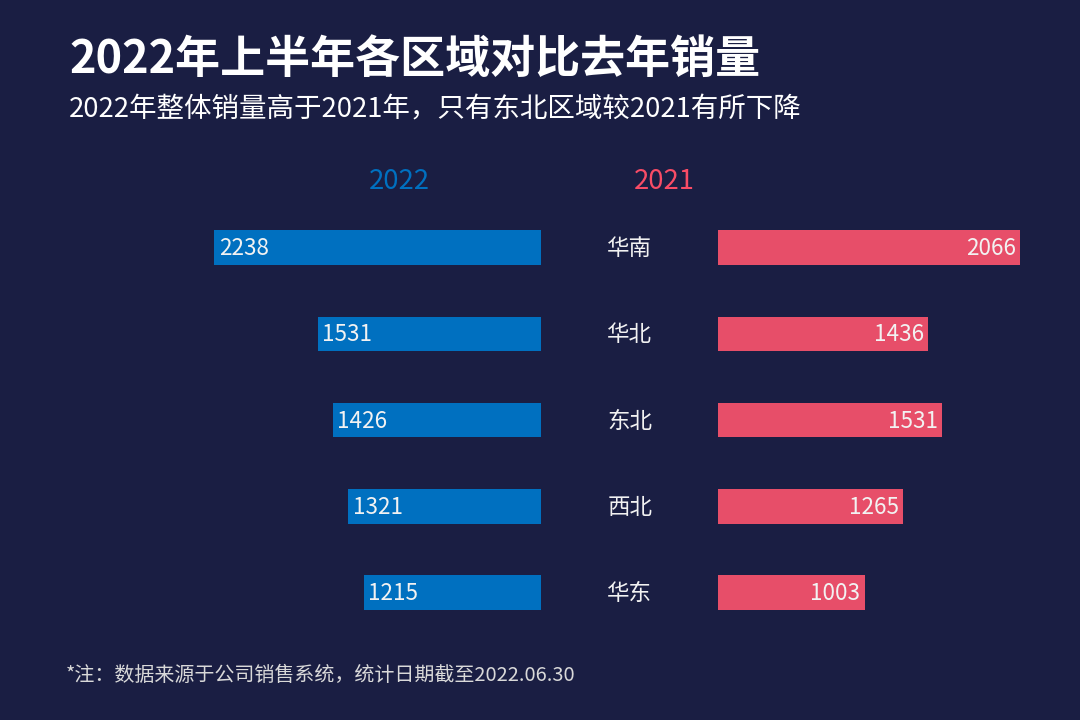

In [7]:
def chart_06(show=True):
    df=read_table(6,'B:F',5)
    left,right=numeric(df,'2022年销量'),numeric(df,'2021年销量')
    # 重算占位：让左侧条形右端对齐，中央留出相同宽度。
    left_edge=left[0]+left[-1]; gap=left[0]
    y=np.arange(len(df)); fig,ax,root=canvas(6)
    ax.set_xlim(0,7000);ax.set_ylim(-.5,4.5);ax.set_xticks([]);ax.set_yticks([])
    ax.barh(y,left,left=left_edge-left,height=.4,color=BLUE)
    ax.barh(y,right,left=left_edge+gap,height=.4,color=PINK)
    for j,(a,b,region) in enumerate(zip(left,right,df['区域'])):
        ax.text(left_edge-a+30,j,f'{a:g}',ha='left',va='center',fontsize=9,color=WHITE)
        ax.text(left_edge+gap+b-30,j,f'{b:g}',ha='right',va='center',fontsize=9,color=WHITE)
        ax.text(left_edge+gap/2,j,region,ha='center',va='center',fontsize=9,color=WHITE)
    template_text(fig,root,skip_text=('                              ',))
    fig.text(.37,.738,'2022',ha='center',fontsize=11,color=BLUE)
    fig.text(.615,.738,'2021',ha='center',fontsize=11,color='#F94C66')
    return finish(fig,6,'蝴蝶图_销量',show)

fig = chart_06()
plt.close(fig)

## 07. 蝴蝶图（百分比）

数据源：Excel 第 7 个工作表，单元格 `B2:D7`，含表头。

以等间距细竖线实现 Excel 的 REPT 条纹效果；左右长度由完成率计算，保留原图区域顺序和百分比。

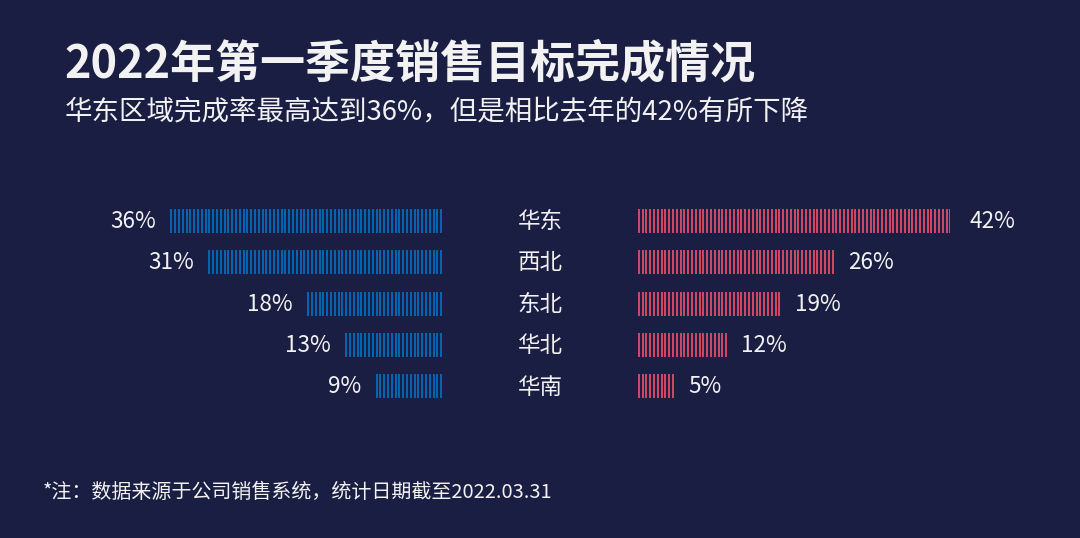

In [8]:
def chart_07(show=True):
    df=read_table(7,'B:D',5)
    left,right=numeric(df,'2022年'),numeric(df,'2021年')
    fig,ax,root=canvas(7)
    ax.set_xlim(-.54,.54);ax.set_ylim(4.8,-.8);ax.set_xticks([]);ax.set_yticks([])
    gap=.13
    for j,(a,b,region) in enumerate(zip(left,right,df['区域'])):
        # REPT("|", 完成率*200) 的代码等价实现：用等间距竖线组成条纹。
        na,nb=int(a*200),int(b*200)
        ax.vlines(-gap-np.arange(na)/200,j-.29,j+.29,color=BLUE,lw=.7)
        ax.vlines(gap+np.arange(nb)/200,j-.29,j+.29,color=PINK,lw=.7)
        ax.text(0,j,region,ha='center',va='center',fontsize=9,color=WHITE)
        ax.text(-gap-a-.015,j,f'{a:.0%}',ha='right',va='center',fontsize=9,color=WHITE)
        ax.text(gap+b+.015,j,f'{b:.0%}',ha='left',va='center',fontsize=9,color=WHITE)
    fig.text(.06,.922,'2022年第一季度销售目标完成情况',fontsize=18,weight='bold',color=WHITE,va='top')
    fig.text(.06,.815,'华东区域完成率最高达到36%，但是相比去年的42%有所下降',fontsize=11,color=WHITE,va='top')
    fig.text(.04,.075,'*注：数据来源于公司销售系统，统计日期截至2022.03.31',fontsize=8,color=WHITE)
    return finish(fig,7,'蝴蝶图_百分比',show)

fig = chart_07()
plt.close(fig)

## 08. 数值百分比

数据源：Excel 第 8 个工作表，单元格 `B2:F8`，含表头。

将销量、补齐占位和同比标签区分成三段；销量数字放在深蓝段末端，同比数值置于红色区域。

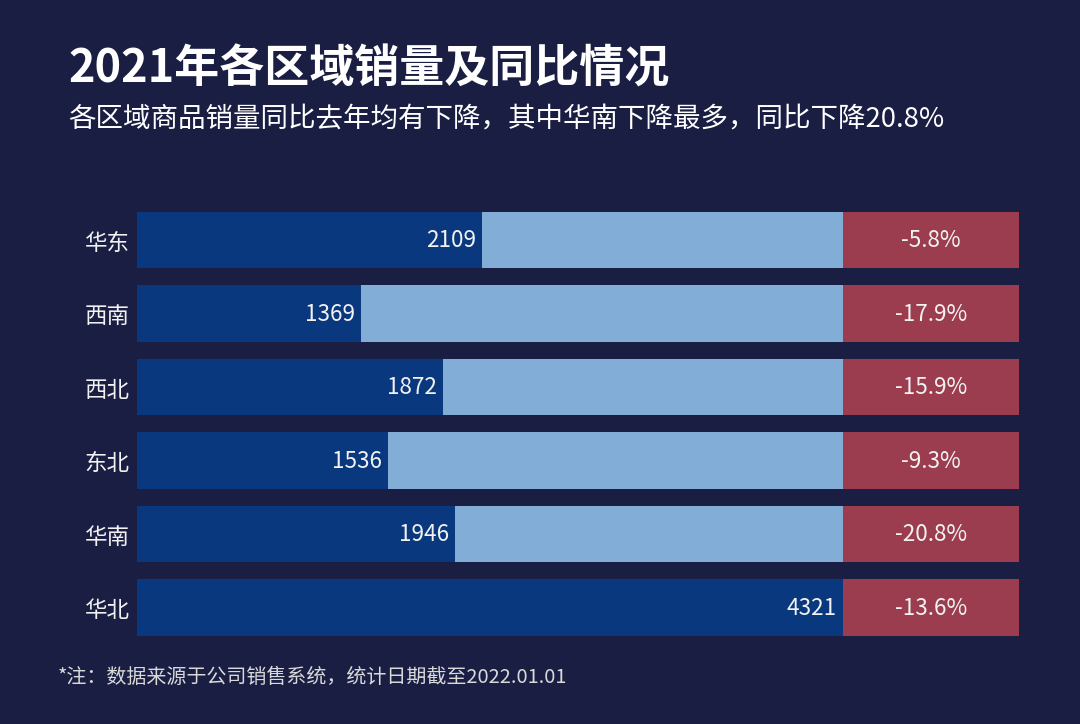

In [9]:
def chart_08(show=True):
    df=read_table(8,'B:F',6)
    y=np.arange(len(df)); sales=numeric(df,'销量'); yoy=numeric(df,'同比去年')
    max_sales=sales.max(); tail=max_sales/4
    fig,ax,root=canvas(8)
    ax.set_xlim(0,max_sales+tail);ax.set_ylim(-.5,len(df)-.5)
    ax.set_xticks([]);ax.set_yticks(y,df['区域']);ax.tick_params(axis='y',pad=3)
    ax.barh(y,sales,height=1/1.3,color='#09387E')
    ax.barh(y,max_sales-sales,left=sales,height=1/1.3,color=LIGHT_BLUE)
    ax.barh(y,np.full(len(df),tail),left=max_sales,height=1/1.3,color='#9B3D4F')
    for j,(s,p) in enumerate(zip(sales,yoy)):
        ax.text(s-35,j,f'{s:g}',ha='right',va='center',fontsize=9,color=WHITE)
        ax.text(max_sales+tail/2,j,f'{p:.1%}',ha='center',va='center',fontsize=9,color=WHITE)
    template_text(fig,root)
    return finish(fig,8,'数值百分比',show)

fig = chart_08()
plt.close(fig)

## 09. 对比柱形图

数据源：Excel 第 9 个工作表，单元格 `B2:E7`，含表头。

并列显示两年销量，差值按两年销量相减重新计算，用竖向比较线、白色方形端点及差值标签表达。

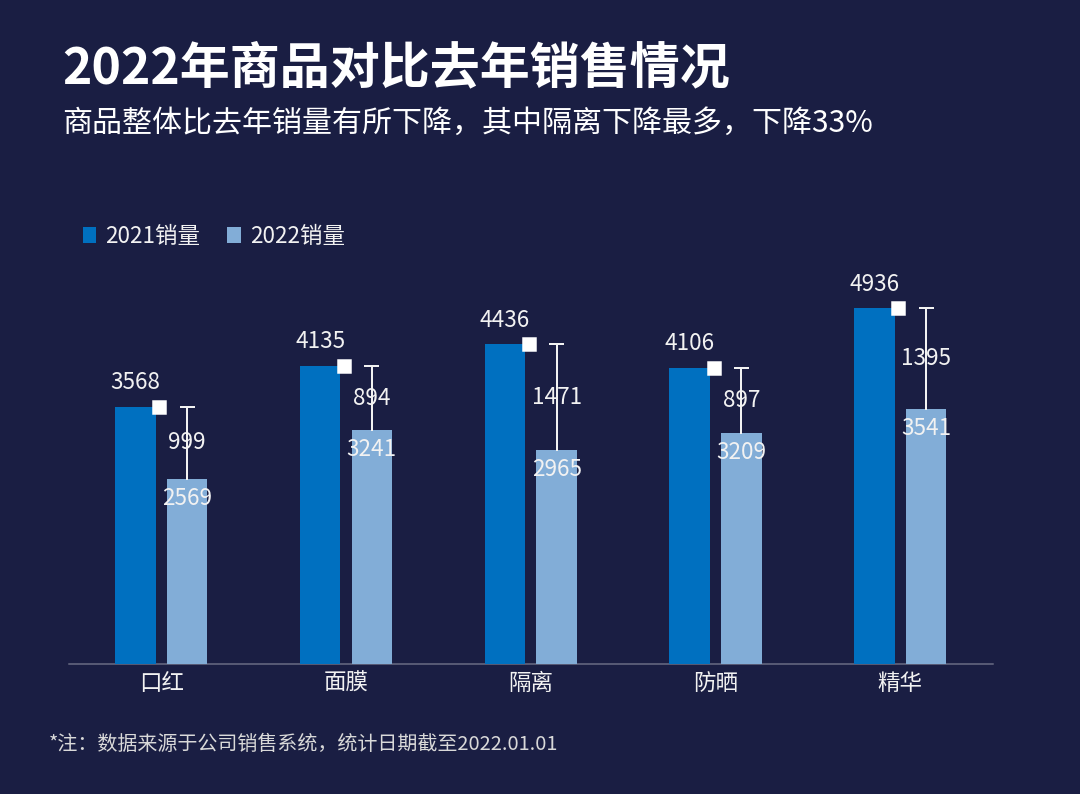

In [10]:
def chart_09(show=True):
    df=read_table(9,'B:E',5)
    old,new=numeric(df,'2021销量'),numeric(df,'2022销量')
    difference=old-new
    x=np.arange(len(df));fig,ax,root=canvas(9)
    category_axis(ax,df['商品'].tolist(),6000,grid=False,ylabels=False,baseline=True)
    width=.22; off=.14
    bars1=ax.bar(x-off,old,width=width,color=BLUE,zorder=3,label='2021销量')
    bars2=ax.bar(x+off,new,width=width,color=LIGHT_BLUE,zorder=3,label='2022销量')
    value_labels(ax,x-off,old,offset=5)
    for xi,a,b,delta in zip(x,old,new,difference):
        ax.text(xi+off,b-110,f'{b:g}',ha='center',va='top',fontsize=9,color=WHITE,zorder=8)
        ax.plot([xi+off,xi+off],[b,a],color=WHITE,lw=.8,zorder=5)
        ax.plot([xi+off-.035,xi+off+.035],[a,a],color=WHITE,lw=.8,zorder=5)
        ax.plot([xi-.01],[a],marker='s',ms=4.5,color='white',zorder=6)
        ax.text(xi+off,(a+b)/2,f'{delta:g}',ha='center',va='center',fontsize=9,color=WHITE,zorder=8)
    legend=fig.legend([bars1,bars2],['2021销量','2022销量'],loc='upper left',
                     bbox_to_anchor=(.058,.742),frameon=False,ncol=2,fontsize=9,
                     handlelength=.6,handletextpad=.4,columnspacing=1.2)
    for t in legend.get_texts():t.set_color(WHITE)
    template_text(fig,root)
    return finish(fig,9,'对比柱形图',show)

fig = chart_09()
plt.close(fig)

## 10. 甘特图

数据源：Excel 第 10 个工作表，单元格 `B3:G10`，含表头。

横轴读取开始日期，完整条长表示项目天数，浅蓝部分表示完成度，百分比居中显示。

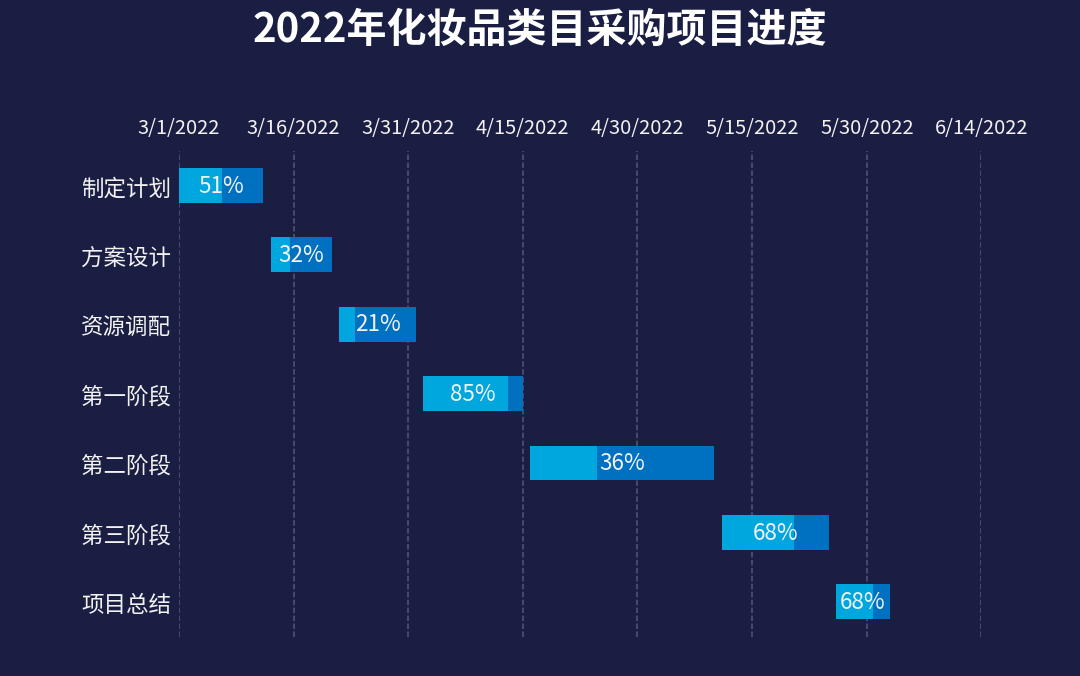

In [11]:
def chart_10(show=True):
    df=read_table(10,'B:G',7,header=2)
    starts=df['开始日期']
    if pd.api.types.is_numeric_dtype(starts):
        starts=pd.to_datetime(starts,unit='D',origin='1899-12-30')
    else:starts=pd.to_datetime(starts)
    start_numbers=(starts-pd.Timestamp('1899-12-30')).dt.total_seconds().to_numpy()/86400
    duration,completion=numeric(df,'项目天数'),numeric(df,'完成度')
    y=np.arange(len(df));fig,ax,root=canvas(10)
    ax.set_xlim(44621,44726);ax.set_ylim(len(df)-.5,-.5)
    ax.set_yticks(y,df['项目名称']);ticks=np.arange(44621,44727,15)
    dates=pd.to_datetime(ticks,unit='D',origin='1899-12-30')
    ax.set_xticks(ticks,[f'{d.month}/{d.day}/{d.year}' for d in dates])
    ax.xaxis.tick_top();ax.tick_params(axis='x',labelsize=8,pad=5)
    ax.xaxis.grid(True,color=WHITE,alpha=.28,ls='--',lw=.6)
    ax.barh(y,duration,left=start_numbers,height=.5,color=BLUE,zorder=3)
    ax.barh(y,duration*completion,left=start_numbers,height=.5,color='#00A7DF',zorder=4)
    for j,(s,d,p) in enumerate(zip(start_numbers,duration,completion)):
        ax.text(s+d/2,j,f'{p:.0%}',ha='center',va='center',fontsize=9,color=WHITE,zorder=6)
    template_text(fig,root)
    return finish(fig,10,'甘特图',show)

fig = chart_10()
plt.close(fig)

## 11. 平滑折线图

数据源：Excel 第 11 个工作表，单元格 `B2:D13`，含表头。

原始点保持不变，用保形三次插值生成平滑曲线；标出峰值及年份色带。平滑算法与 Excel 内置算法可能有细微差别。

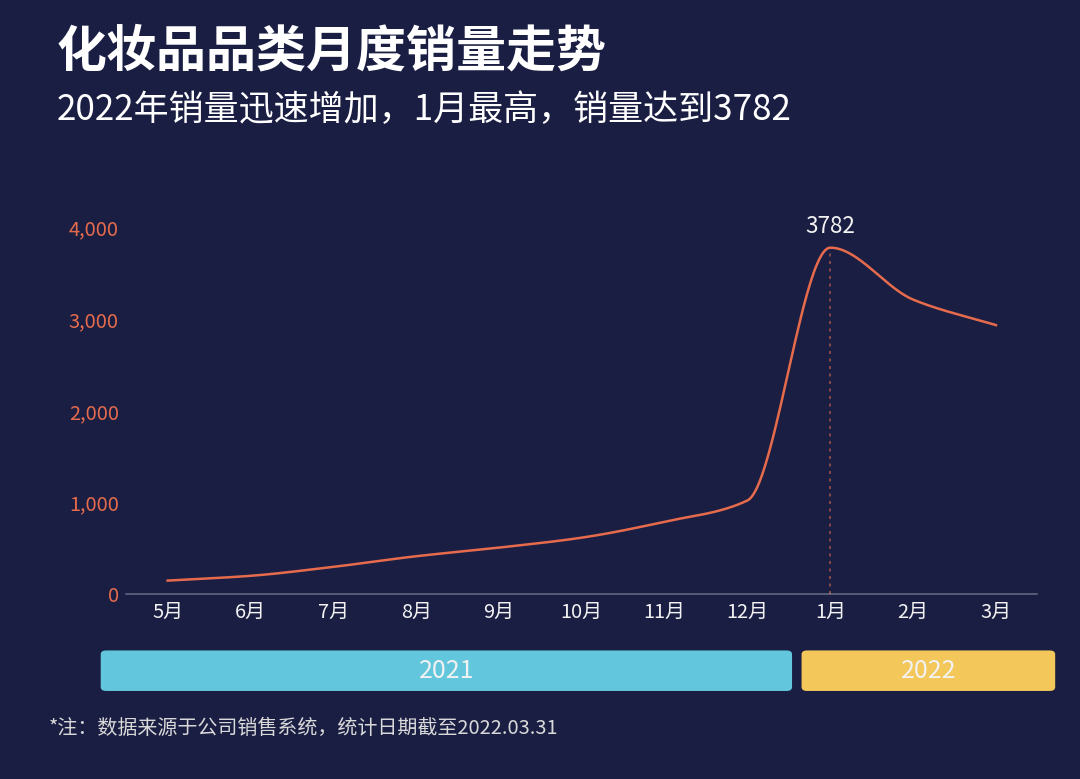

In [12]:
def chart_11(show=True):
    df=read_table(11,'B:D',11)
    y=numeric(df,'销量');x=np.arange(len(y));xx,yy=smooth_curve(x,y)
    fig,ax,root=canvas(11)
    category_axis(ax,df['月份'].tolist(),4000,1000,grid=False,baseline=True)
    ax.tick_params(axis='x',labelsize=8)
    ax.tick_params(axis='y',labelsize=8,colors='#E66B4C')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'))
    ax.plot(xx,yy,color='#E66B4C',lw=1)
    peak=int(np.argmax(y))
    ax.annotate(f'{y[peak]:g}',(peak,y[peak]),xytext=(0,4),textcoords='offset points',
                ha='center',va='bottom',fontsize=9,color=WHITE)
    ax.vlines(peak,0,y[peak],color='#E66B4C',ls=(0,(2,3)),lw=.6,alpha=.7)
    template_text(fig,root,skip_exact=('2021','2022'))
    # 年份色带的位置和配色沿用原模板。
    for x0,w,year,c in [(.09325,.64013,'2021','#62C7DC'),(.74219,.23483,'2022','#F4C75B')]:
        patch=FancyBboxPatch((x0,.113),w,.052,boxstyle='round,pad=0,rounding_size=.005',
                            transform=fig.transFigure,facecolor=c,edgecolor='none')
        fig.patches.append(patch)
        fig.text(x0+w/2,.139,year,ha='center',va='center',fontsize=10,color=WHITE)
    return finish(fig,11,'平滑折线图',show)

fig = chart_11()
plt.close(fig)

## 12. 菱形走势图

数据源：Excel 第 12 个工作表，单元格 `B2:C10`，含表头。

源文件将连接线设为 noFill，因此仅保留空心菱形与百分比标注；百分比保留两位小数。

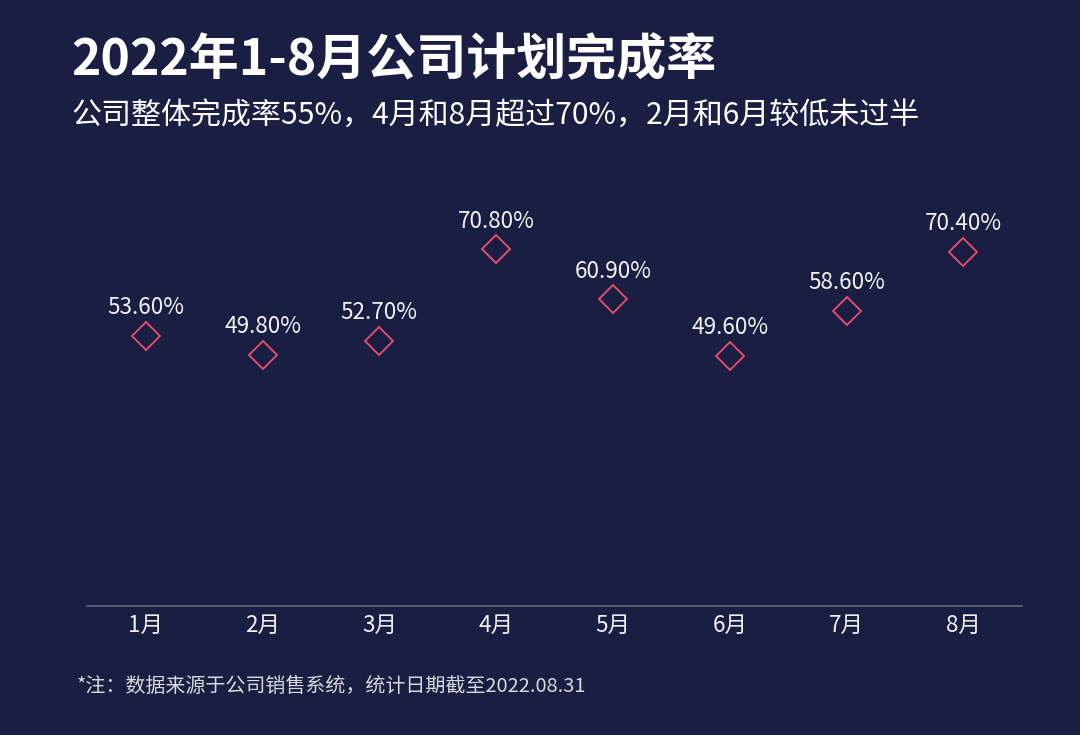

In [13]:
def chart_12(show=True):
    df=read_table(12,'B:C',8)
    y=numeric(df,'完成率');x=np.arange(len(y));fig,ax,root=canvas(12)
    category_axis(ax,df['月份'].tolist(),.8,grid=False,ylabels=False,baseline=True)
    # 源文件连接线为 noFill：只画空心菱形，不擅自增加折线。
    ax.plot(x,y,linestyle='none',marker='D',ms=8,mfc=BG,mec=PINK,mew=.75)
    for xi,yi in zip(x,y):
        ax.annotate(f'{yi:.2%}',(xi,yi),xytext=(0,7),textcoords='offset points',
                    ha='center',va='bottom',fontsize=9,color=WHITE)
    template_text(fig,root)
    return finish(fig,12,'菱形走势图',show)

fig = chart_12()
plt.close(fig)

## 13. 对比折线图

数据源：Excel 第 13 个工作表，单元格 `B2:D8`，含表头。

保留双系列折线、圆形节点和右上方图例，根据高低关系调整数字位置以避免重叠。

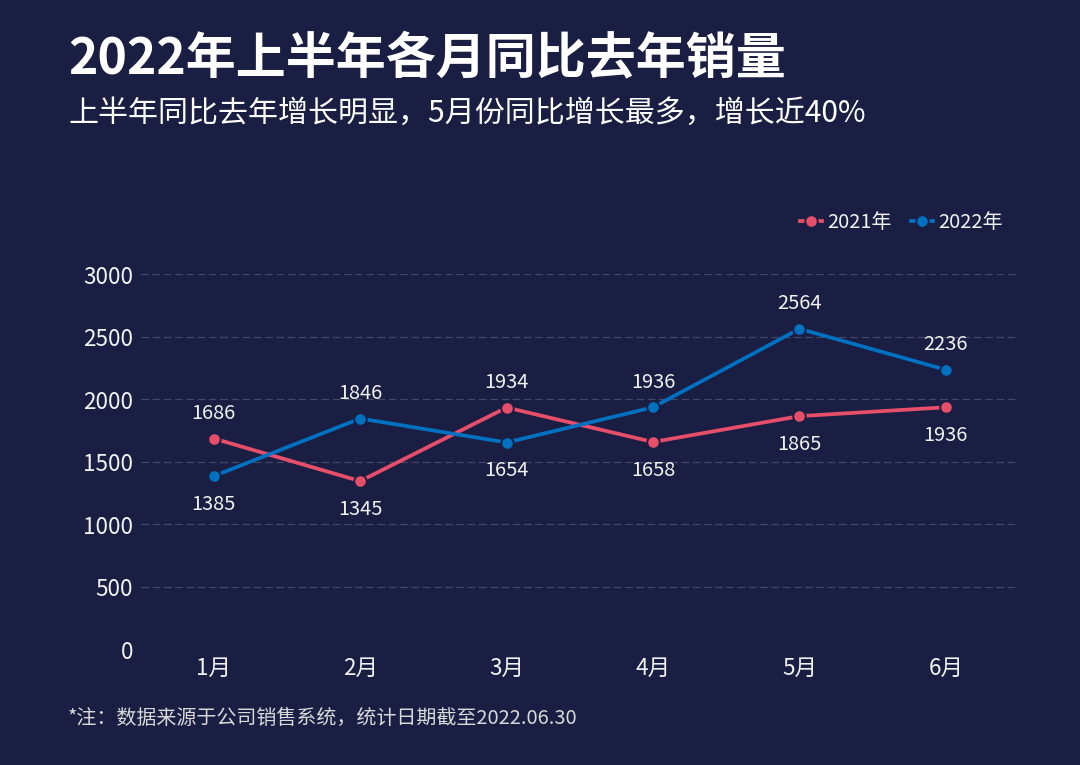

In [14]:
def chart_13(show=True):
    df=read_table(13,'B:D',6)
    old,new=numeric(df,'2021年'),numeric(df,'2022年')
    x=np.arange(len(df));fig,ax,root=canvas(13)
    category_axis(ax,df['月份'].tolist(),3000,500)
    line1,=ax.plot(x,old,color=PINK,lw=1.5,marker='o',ms=5,mec=BG,mew=.75,label='2021年')
    line2,=ax.plot(x,new,color=BLUE,lw=1.5,marker='o',ms=5,mec=BG,mew=.75,label='2022年')
    for xi,a,b in zip(x,old,new):
        old_above = a >= b
        ax.annotate(f'{a:g}',(xi,a),xytext=(0,6 if old_above else -7),textcoords='offset points',
                    ha='center',va='bottom' if old_above else 'top',fontsize=8,color=WHITE)
        ax.annotate(f'{b:g}',(xi,b),xytext=(0,-7 if old_above else 6),textcoords='offset points',
                    ha='center',va='top' if old_above else 'bottom',fontsize=8,color=WHITE)
    legend=fig.legend([line1,line2],['2021年','2022年'],loc='upper right',
                      bbox_to_anchor=(.945,.746),frameon=False,ncol=2,fontsize=8,
                      handlelength=1.1,handletextpad=.25,columnspacing=1)
    for t in legend.get_texts():t.set_color(WHITE)
    template_text(fig,root)
    return finish(fig,13,'对比折线图',show)

fig = chart_13()
plt.close(fig)

## 14. 单值圆环图

数据源：Excel 第 14 个工作表，单元格 `B2:C3`，含表头。

完成率读取 B3，起始角读取原模板设计；按源 XML 的 90% 内径绘制细环，使用紫红渐变。部分办公软件会将该参数渲染成更粗的环。

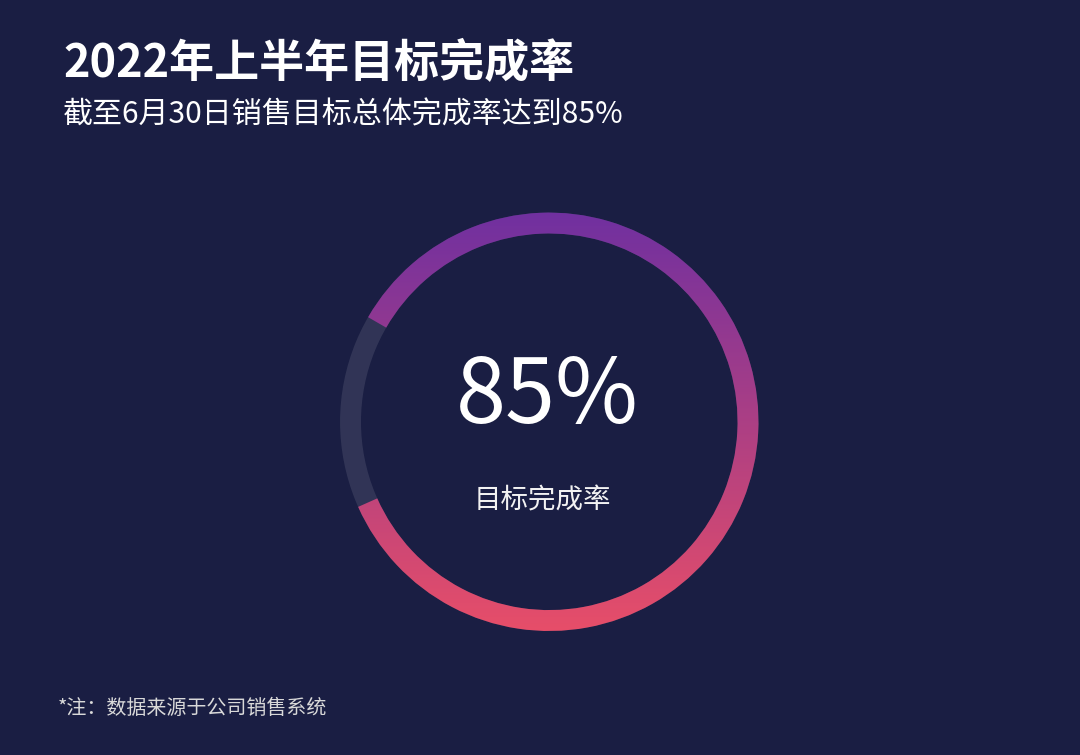

In [15]:
def chart_14(show=True):
    df=read_table(14,'B:C',1)
    p=float(df.loc[0,'完成率'])
    if not 0<=p<=1:raise ValueError('完成率必须介于 0 和 1 之间。')
    fig,ax,root=canvas(14)
    ax.set_aspect('equal');ax.set_xlim(-1.02,1.02);ax.set_ylim(-1.02,1.02);ax.axis('off')
    # 原生 XML 设置 holeSize=90；保留 90% 的内径，而非渲染器的默认粗环。
    hole=.90
    ax.add_patch(Wedge((0,0),1,0,360,width=1-hole,facecolor=(1,1,1,.1),edgecolor='none'))
    # Excel firstSliceAng=300，从左上 150° 起顺时针填充。
    mask=Wedge((0,0),1,150-360*p,150,width=1-hole,facecolor='none',edgecolor='none')
    ax.add_patch(mask)
    ramp=np.linspace(0,1,600)[:,None,None]
    bottom=np.array(colors.to_rgba('#E74E69'));top=np.array(colors.to_rgba('#7030A0'))
    im=ax.imshow(bottom[None,None,:]*(1-ramp)+top[None,None,:]*ramp,
                 extent=(-1,1,-1,1),origin='lower',interpolation='bicubic',zorder=3)
    im.set_clip_path(mask)
    template_text(fig,root,{'85%':f'{p:.0%}'})
    return finish(fig,14,'单值圆环图',show)

fig = chart_14()
plt.close(fig)

## 15. 水球图

数据源：Excel 第 15 个工作表，单元格 `B2:C3`，含表头。

以圆形路径裁切蓝色矩形，水位高度和中心数字均从完成率计算。采用几何绘图替代 Excel 图片填充的堆叠机制。

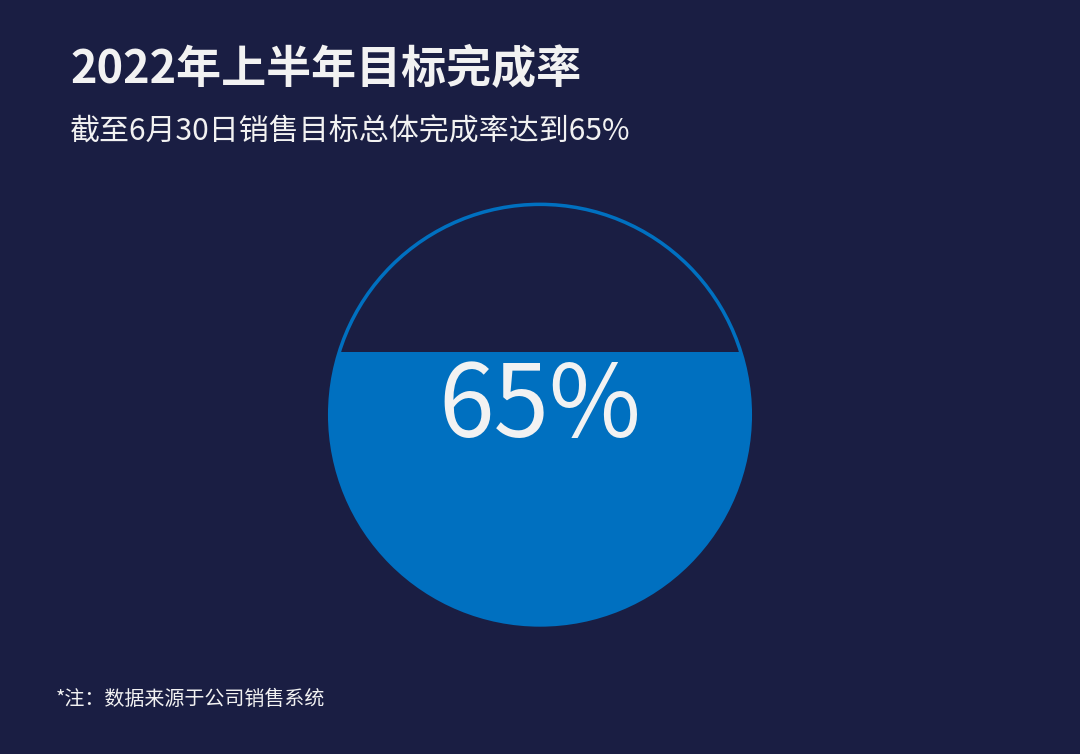

In [16]:
def chart_15(show=True):
    df=read_table(15,'B:C',1)
    p=float(df.loc[0,'完成率'])
    if not 0<=p<=1:raise ValueError('完成率必须介于 0 和 1 之间。')
    fig,ax,root=canvas(15)
    ax.set_position([.26,.16,.48,.58]);ax.set_aspect('equal')
    ax.set_xlim(-1.04,1.04);ax.set_ylim(-1.04,1.04);ax.axis('off')
    # 圆形边界 + 按数值计算的水位 + 圆形裁切；不使用固定百分比的图片。
    boundary=Circle((0,0),1,facecolor='none',edgecolor=BLUE,lw=1.4,zorder=5)
    ax.add_patch(boundary)
    water=Rectangle((-1,-1),2,2*p,facecolor=BLUE,edgecolor='none',zorder=3)
    ax.add_patch(water);water.set_clip_path(boundary)
    ax.text(0,.03,f'{p:.0%}',ha='center',va='center',fontsize=40,color=WHITE,zorder=8)
    fig.text(.065,.938,'2022年上半年目标完成率',fontsize=18,weight='bold',color=WHITE,va='top')
    fig.text(.065,.845,f'截至6月30日销售目标总体完成率达到{p:.0%}',fontsize=12,color=WHITE,va='top')
    fig.text(.052,.065,'*注：数据来源于公司销售系统',fontsize=8,color=WHITE)
    return finish(fig,15,'水球图',show)

fig = chart_15()
plt.close(fig)

## 完成

已生成 15 张 PNG。如需只重画某一张图，先执行第 0 节公共设置，再执行对应图表的代码单元格。Excel 文件请保留原有工作表名称、数据位置和图表样式对象；标题与布局工具会读取其中的样式。